In [1]:
from pathlib import Path

from signal_processing import *

# Load the raw dataset. The loader adds timestamp_ms and time_seconds.
szeli_measurements = data_load("functional_tests/measurements/fdc1004_data_Szeli_K.csv")

In [2]:
# Transform only CIN_2. The CIN_4_pF column remains unchanged.
cin2_smoothed = moving_average(
    measurements,
    window_size=5,
    channels="CIN_2",
)

# Transform both channels. Each transform returns a new DataFrame, so
# measurements and cin2_smoothed are still available as raw/intermediate data.
rms = moving_rms(
    measurements,
    window_size=20,
    channels="both",
)
movement = threshold_transform(
    rms,
    threshold=0.01,
    channels=["CIN_2", "CIN_4"],
)

# Apply a high-pass filter to CIN_4. The sampling frequency is inferred
# from timestamp_ms when it is not supplied explicitly.
cin4_highpass = highpass_transform(
    measurements,
    cutoff_frequency=0.1,
    channels="CIN_4",
)

# Print a few rows from every result.
print("Raw data:")
print(measurements.head())
print("\nSmoothed CIN_2:")
print(cin2_smoothed[["time_seconds", "CIN2_pF"]].head())
print("\nBinary movement classification:")
print(movement[["time_seconds", "CIN2_pF", "CIN4_pF"]].head())
print("\nHigh-pass filtered CIN_4:")
print(cin4_highpass[["time_seconds", "CIN4_pF"]].head())

# Plot either one channel or both channels. The returned figure and axes
# can be further customized or saved instead of displayed.
plot(measurements, channels="both", title="Raw capacitance measurements")
plot(cin2_smoothed, channels="CIN_2", title="Smoothed CIN_2")
plot(movement, channels="both", title="Movement classification")
plot(cin4_highpass, channels="both", title="High-pass filtered CIN_4")

import matplotlib.pyplot as plt

plt.show()

NameError: name 'measurements' is not defined

(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'Raw capacitance measurements'}, xlabel='Time (seconds)', ylabel='Capacitance'>)

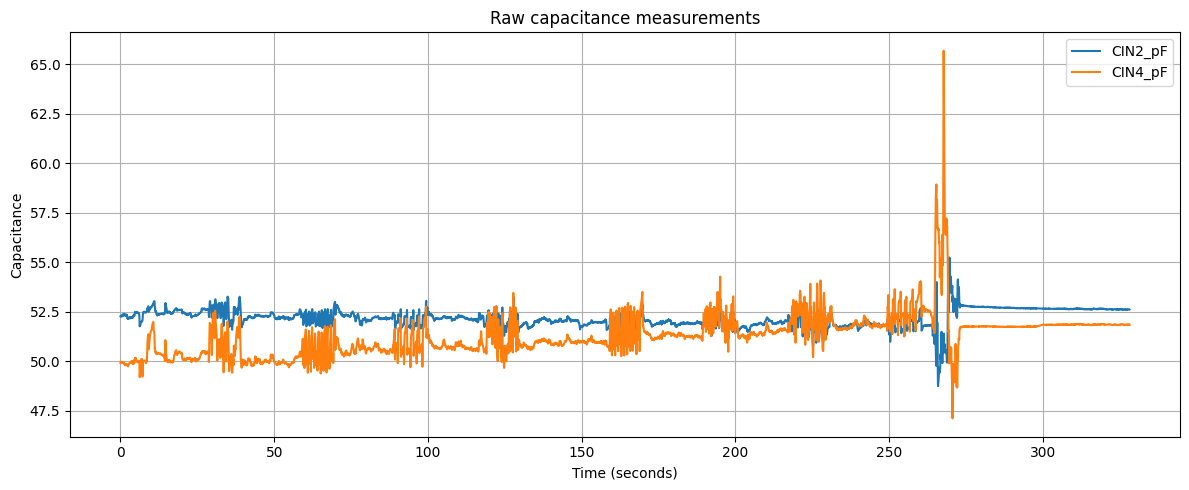

In [3]:
plot(szeli_measurements, channels="both", title="Raw capacitance measurements")

(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'Cut dataset'}, xlabel='Time (seconds)', ylabel='Capacitance'>)

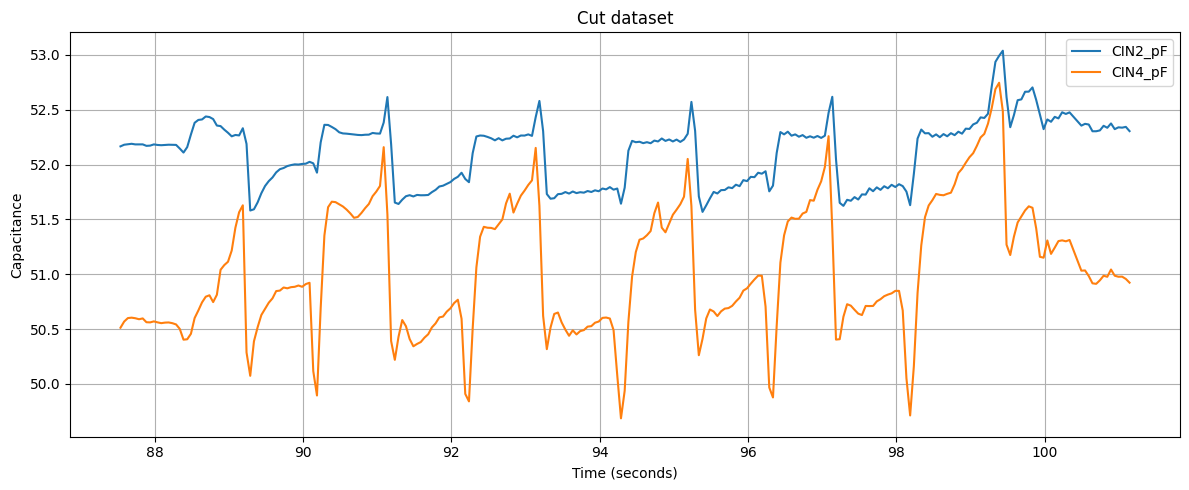

In [35]:
check_movement = cut_dataset(szeli_measurements, start=87.5, end=227)
plot(check_movement, channels="both", title="Cut dataset")

(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'Cut dataset (100-100)'}, xlabel='Time (seconds)', ylabel='Capacitance'>)

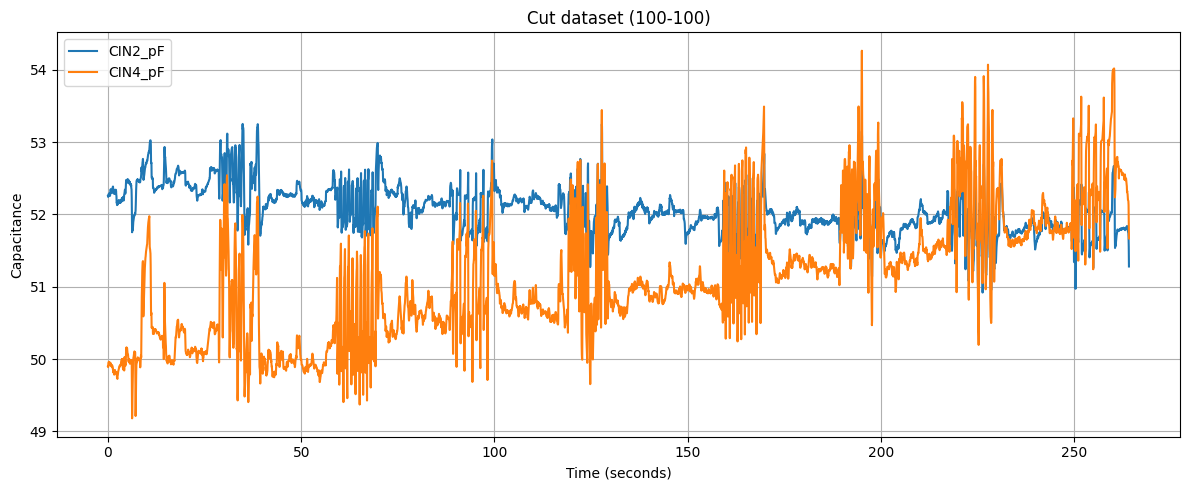

In [12]:
szeli_cut = cut_dataset(szeli_measurements, start=0, end=64)
plot(szeli_cut, channels="both", title="Cut dataset (100-100)")

(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'High-pass filtered CIN_2 and CIN_4'}, xlabel='Time (seconds)', ylabel='Capacitance'>)

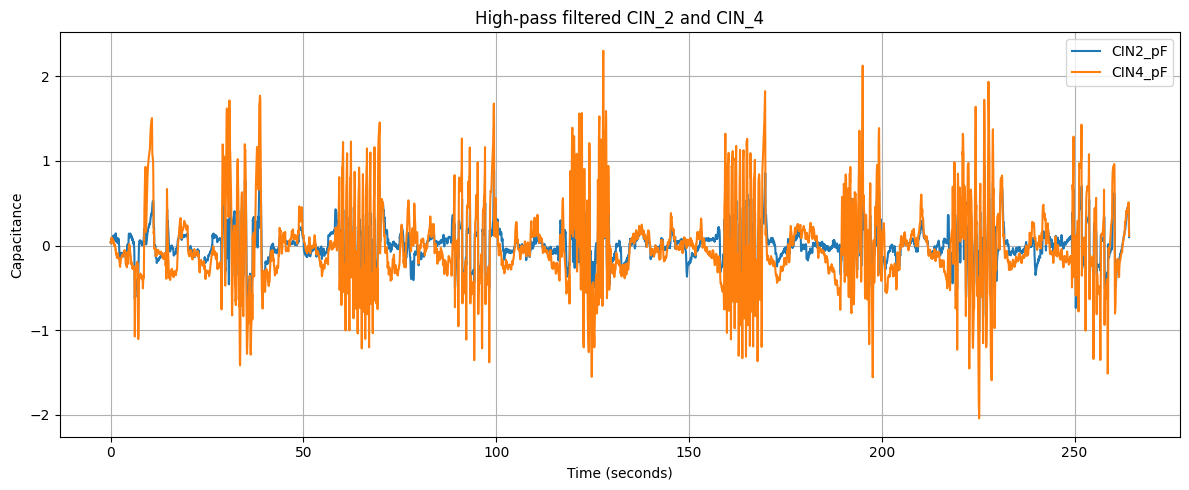

In [13]:
high_pass_filtered = highpass_transform(
    szeli_cut,
    cutoff_frequency=0.05,
    channels="both",
)

plot(high_pass_filtered, channels="both", title="High-pass filtered CIN_2 and CIN_4")

(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'RMS of high-pass filtered CIN_2 and CIN_4'}, xlabel='Time (seconds)', ylabel='Capacitance'>)

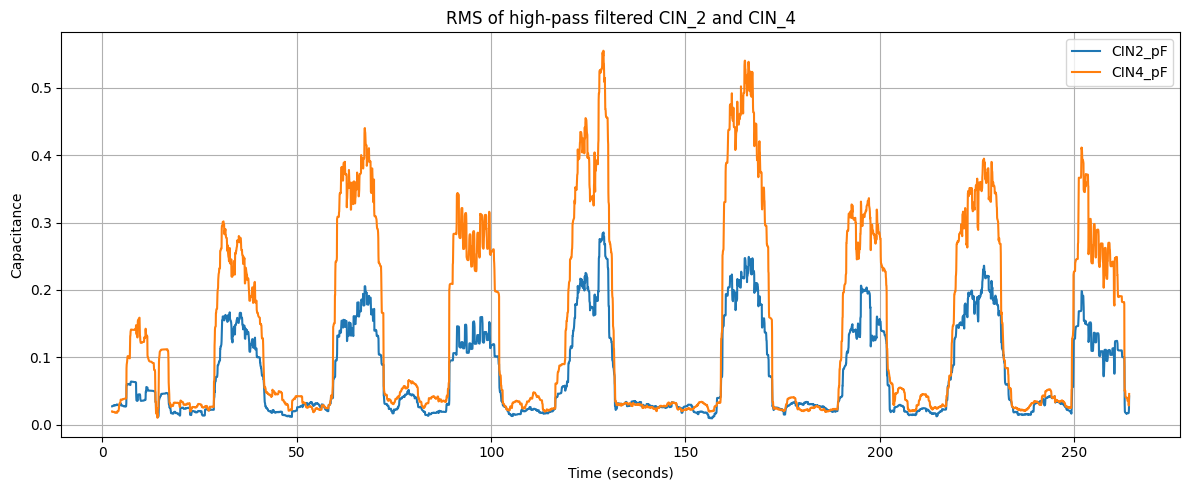

In [ ]:
#20 Hz-es a mérés és 0.5 Hz egy lassú szemmozgás, akkor legalább 40 window_size kell 

szeli_rms = moving_rms(
    high_pass_filtered,
    window_size=50,
    channels="both",
)

plot(szeli_rms, channels="both", title="RMS of high-pass filtered CIN_2 and CIN_4")

(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'Movement classification'}, xlabel='Time (seconds)', ylabel='Capacitance'>)

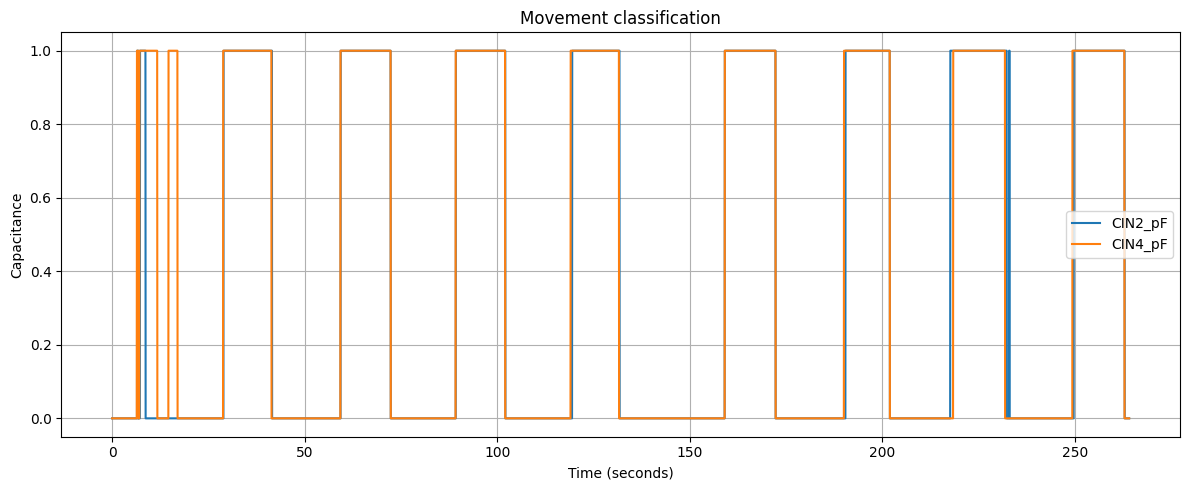

In [43]:
movement_left = threshold_transform(
    szeli_rms,
    threshold=0.06,
    channels="left",
)
movement_both = threshold_transform(
    movement_left,
    threshold=0.1,
    channels="right",
)

plot(movement_both, channels="both", title="Movement classification")